## This analysis is concerned with the enrichment of LASV/Mammarenavirus/Arenavirus-specific peptides by LASV monoclonal antibodies. 

In [35]:
import pandas as pd
df = pd.read_csv('downloads_study920_mapped_rpk.csv').set_index('peptide')

peps_metadata = pd.read_csv('../metadata_files/lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')

In [36]:
from fig_style import apply_style

apply_style()

In [37]:
df_mab_panel_old = pd.read_csv('/data1/sporak/Lassa_fever/Lassa_Fever_growup2/PhIP-Seq/Lassa_Lib/All_source_plates_Analysis/lasv_phipseq_2026/mAb_PhIP-Seq/downloads_study880_mapped_rpk.csv').set_index('peptide')

In [38]:
df_mAb = df.filter(regex='mAb')
df_AG = df.filter(regex='AG')

In [39]:
df_AG_avg = df_AG.mean(axis=1)

In [40]:
df_mAb_fc = (df_mAb + 1).div((df_AG_avg + 1), axis=0)

### filter to Arenavirus peptides and glycoprotein

In [41]:
peps_metadata_arenavirus_gp = peps_metadata.loc[(peps_metadata['genus'] == 'Mammarenavirus') & (peps_metadata['protein_std'] == 'glycoprotein')]
seq_id = peps_metadata_arenavirus_gp['seq_id']

In [42]:
df_mAb_fc_arenaviridae_gp = df_mAb_fc.loc[seq_id]

#### build a dictionary so you can collect each mAb result 

In [43]:
mab_results = {}

def add_mab_result(mab_name, regex, results_dict, **kwargs):
    result = analyze_mab_peptides(regex=regex, **kwargs)

    #store the full result under the chosen mAb name
    results_dict[mab_name] = result

    return result


## now going to investigate each mAb individually - starting with mAbs known to bind linear epitopes (and thus being non-neutralizing)

In [44]:
import numpy as np
import pandas as pd
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices 

def analyze_mab_peptides(
    df, 
    peps_metadata, 
    regex, 
    ref_path="../ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta", 
    target_id="sp|P08669|GLYC_LASSJ", 
    top_n=5, 
    literature_note=None, 
    print_alignments=True,
    min_fc = 50,
    max_replicate_ratio=1.5, 
    min_coverage=0.80
):
    """Select two mAb replicate columns using regex, calculate Pearson's r, only keep if passes 0.95,
    rank peptides by mean enrichment, and align the top peptides to a reference protein. 
    
    Reference coordinates are 1-based and inclusive. 
    Discontinuous covered regions are reported separately. 
    """
    def get_covered_regions(positions):
        """Convert positions into separate contiguous intervals"""
        positions = sorted(set(positions))

        if not positions:
            return[]

        regions = []
        region_start = positions[0]
        region_end = positions[0]

        for position in positions[1:]:

            if position == region_end + 1:
                region_end = position #extend the current region
            else:
                #gap: save the completed region
                regions.append((region_start, region_end))

                #start a new region at the current position
                region_start = position
                region_end = position

        regions.append((region_start, region_end))
        return regions


    """calculate pearson's R for Arenavirus GPC peptides and find top 20 Arenavirus GPC peptides"""
    mAbs = df.filter(regex=regex, axis=1).copy()
    
    mAbs = (mAbs.apply(pd.to_numeric, errors='raise'))

    pearsons_r = mAbs.iloc[:, 0].corr(mAbs.iloc[:, 1], method='pearson')

    print(f"Profile Pearson's r = {pearsons_r:.3f}")
        
    ### ---- Rank peptides by mean enrichment --- only keep peptides with FC > 50

    mAbs = mAbs.loc[(mAbs > min_fc).all(axis=1)] # e.g. FC > 50 in both replicates

    #measure agreement for each peptide
    #example: 85.4 and 88.7 give a ratio of approximately 1.04

    replicate_ratio = mAbs.max(axis=1) / mAbs.min(axis=1)

    #keep peptides whose replicate values differ by no more than the chosen multiplicative factor
    mAbs = mAbs.loc[replicate_ratio <= max_replicate_ratio]

    if mAbs.empty:
        print(f"No peptides passed the enrichment and replicate_agreement filters")
        return None

    #a peptide needs values in both replicates. ranking the remaining peptides. 
    mAbs_avg = mAbs.mean(axis=1, skipna=False)

    mAbs_top = mAbs_avg.dropna().sort_values(ascending=False).head(top_n).rename("mean_fc")


    ### --- retrieve metadata 
    mAbs_top_pep_sequences = peps_metadata.loc[peps_metadata['seq_id'].isin(mAbs_top.index.to_list())]

    """alignment part""" #---- Load reference

    #SeqIO.to_dict() expects parsed sequence records
    ref_records = SeqIO.to_dict(SeqIO.parse(ref_path, 'fasta'))

    target_id = "sp|P08669|GLYC_LASSJ"
    ref_seq = ref_records[target_id].seq

    #------- configure pairwise aliger for peptides 

    aligner = Align.PairwiseAligner()
    aligner.mode = 'local' #for peptides
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5

    #align each peptide to the reference sequence
    peptides = mAbs_top_pep_sequences['sequence'].to_list()

    positions_covered = set()

    for _, row in mAbs_top_pep_sequences.iterrows():

        peptide_id = row['seq_id']

        pep = str(row['sequence']).strip().upper()

        alignments = aligner.align(ref_seq, pep)
        best_alignment = alignments[0] #top scoring alignment

        if best_alignment is None: 
            continue

        aligned_length = sum(end - start for start, end in best_alignment.aligned[1]) #aligned[0] would be aligned blocks in the reference, aligned[1] aligned blocks in the peptide

        coverage = aligned_length / len(pep)

        if coverage < min_coverage:
            continue

        #All aligned blocks; convert to 1-based inclusive positions
        for ref_start, ref_end in best_alignment.aligned[0]:
            positions_covered.update(
                range(int(ref_start) + 1, int(ref_end) +1) #inside range() need ref_end+1, because python excludes the stopping value
            )
        
        if print_alignments:
            print(f"\nPeptide ID: {peptide_id}")
            print(f"Peptide: {pep} | Score: {best_alignment.score}")
            print(best_alignment)


    covered_regions = get_covered_regions(positions_covered)

    print(f"\nResults for {regex}")
    print(f"Pearson's r = {pearsons_r:.3f}")
    print(f"Top peptides selected {len(mAbs_top)}")
    print(f"Covered reference regions (1-based, inclusive) {covered_regions}")


    if literature_note:
        print(literature_note)

    return {
        "pearsons_r": pearsons_r,
        "top_peptides": peptides,
        "peptides enrichment values": mAbs_top,
        "covered_regions": covered_regions,
        "positions_covered": sorted(positions_covered),
    }


    

In [45]:
result = add_mab_result(
    mab_name="1.1B", 
    regex=r"1-1B",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports LASV 1.1B to bind a linear epitope within the T-loop (GP2-L2) of the GP2 subunit of GPC, mapped to residues aa361-375, non-neutralizing"
)

Profile Pearson's r = 0.997

Peptide ID: XOB76280.1|glycoprotein|Mammarenavirus_ryukyuense|CXMIX-YNSF117|Mus_musculus|China:_Yunnan|2021|S|?|tile_17
Peptide: YCNYSKFWYLEHAKTGETSVPKCWLVTNGSYLNETHFSDQIEQEAD | Score: 225.0
target          362 YCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQAD 408
                  0 ||||||.|||.|..||.||.||||||.||||||||||||.|||.||  46
query             0 YCNYSKFWYLEHAKTGETSVPKCWLVTNGSYLNETHFSDQIEQEAD  46


Peptide ID: WDW20703.1|precursor|Ngerengere_mammarenavirus|TZ23187|Mus_minutoides_SE|Tanzania:_Mkundi|08-Dec-2009|S|?|tile_17
Peptide: YSKFWYLEHYKTGETSLPKCWLVSNGSYLNETHFSTEIEQEADNMI | Score: 217.0
target          365 YSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMI 411
                  0 |||.|||.|..||.|||||||||||||||||||||..|||.|||||  46
query             0 YSKFWYLEHYKTGETSLPKCWLVSNGSYLNETHFSTEIEQEADNMI  46


Peptide ID: YP_006858706.1|precursor|Lunk_virus_NKS-1|?|Mus_minutoides|Zambia:Lusaka|10-Aug-2010|S|NKS-1|tile_17
Peptide: YSKFWYLEHYKTGETSLPKCWLVSNGSYLNE

In [46]:
result = add_mab_result(
    mab_name="13.4E", 
    regex=r"13-4E",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports LASV 1.1B to bind a linear epitope within the T-loop (GP2-L2) of the GP2 subunit of GPC, mapped to residues aa361-375, non-neutralizing"
)

Profile Pearson's r = 0.997

Peptide ID: XOB76283.1|precursor|Yunnan_rodent_mammarenavirus_1|HHJP-YNSC97|Niviventer_fulvescens|China:_Yunnan|2021|?|?|tile_17
Peptide: KFWYLNNTKTGQVSLPQCWLISNGSYLNETHFSADIEREANNLITE | Score: 204.0
target          367 KYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITE 413
                  0 |.||||.|.||..|||.|||.||||||||||||.|||..|.|.|||  46
query             0 KFWYLNNTKTGQVSLPQCWLISNGSYLNETHFSADIEREANNLITE  46


Peptide ID: QWQ58032.1|precursor|Bitu_virus|ANG0070|Micaelamys_namaquensis|Angola:_Tundavala|Jul-2017|S|?|tile_17
Peptide: LGIPYCNYTKFWYLNSTRTGHHSLPKCWMISNGSYLNETHFSTEIE | Score: 217.0
target          358 MGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIE 404
                  0 .|||||||.|.||||.|.||..||||||..||||||||||||..||  46
query             0 LGIPYCNYTKFWYLNSTRTGHHSLPKCWMISNGSYLNETHFSTEIE  46


Peptide ID: AZI96476.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_119|Homo_sapiens|Nigeria:_EDO|25-Feb-2018|S|?|tile_16
Peptide: DQLI

In [47]:
result = add_mab_result(
    mab_name="22.5D", 
    regex=r"22-5D",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports LASV 22-5D to bind linear-epitope region (GP2-L1) between fusion loop (aa279-295) and HR1 (aa295-363)"
)

Profile Pearson's r = 0.995

Peptide ID: UUL71807.1|precursor|Mafiga_mammarenavirus|TZ29841|Lemniscomys_rosalia|Tanzania:_Komtema|03-Jul-2016|S|?|tile_14
Peptide: TAVAKCNLNHDEEFCDMLRLIDFNKQAVRRLKNETQLGLRLVTKAV | Score: 180.0
target          295 TAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAV 341
                  0 |||||||..|||||||||||.||||||..|||.|.|....|..|||  46
query             0 TAVAKCNLNHDEEFCDMLRLIDFNKQAVRRLKNETQLGLRLVTKAV  46


Peptide ID: YP_001649222.1|precursor|Mammarenavirus_cupixiense|?|?|?|?|S|BeAn_119303|tile_13
Peptide: LKCFGNTALAKCNLKHDSEFCDMIKLFDFNKNAISKLNNNTIEAVN | Score: 170.0
target          289 LKCFGNTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLIN 338
                  0 ||||||||.||||.|||.|||||..||||||.||..|.---...|...|  49
query             0 LKCFGNTALAKCNLKHDSEFCDMIKLFDFNKNAISKLN---NNTIEAVN  46


Peptide ID: YP_001649226.1|precursor|Mammarenavirus_bearense|?|Peromyscus_californicus|USA:_southern_California|?|S|AV_A0070039|tile_13
Peptide: ASELKCFGNTAVAKCNINHDSEFCDML

In [48]:
result = add_mab_result(
    mab_name="24.6C", 
    regex=r"24-6C",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports LASV 24-6C to bind linear-epitope region (GP2-L3) HR2 region, aa400-412"
)

Profile Pearson's r = 0.984

Peptide ID: WAD86895.1|glycoprotein|Mammarenavirus_lassaense|?|Homo_sapiens|Nigeria|1977|S|GA391|tile_18
Peptide: YLNETKFSDDIEQQADNMITEMLQKEYIDRQGKTPLGLVDLFVFST | Score: 222.0
target          392 YLNETHFSDDIEQQADNMITEMLQKEYMERQGKTPLGLVDLFVFST 438
                  0 |||||.|||||||||||||||||||||..|||||||||||||||||  46
query             0 YLNETKFSDDIEQQADNMITEMLQKEYIDRQGKTPLGLVDLFVFST  46


Peptide ID: QNC69528.1|precursor|Mammarenavirus_lassaense|BEN-16090|Homo_sapiens|Benin|13-Mar-2016|S|?|tile_17
Peptide: WYLNHTSSGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEML | Score: 247.0
target          369 WYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEML 415
                  0 ||||||..||||||||||||||||||||||||||||||||||||||  46
query             0 WYLNHTSSGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEML  46


Peptide ID: AZI96360.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_023|Homo_sapiens|Nigeria:_EDO|18-Jan-2018|S|?|tile_18
Peptide: YLNETHFSDDIEQQADNMITELLQKEYIDRQ

### now looking at GPC-B mAbs - first neutralizing

In [49]:
result = add_mab_result(
    mab_name="18.5C", 
    regex=r"18-5C",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports LASV 18.5C to bind a quaternary pre-fusion epitope. Site A: GP1 N-terminal loop \
aa62-63, GP2 HR2 aa356-362, GP2 T-Loop and HR2 aa387-408. N395 (with glycan), H398, Q405, and D408 sit directly at the binding interface. \
site B: GP2 fusion peptide aa266-275, and GP2 HR1 aa324-326. Unlike other GPC-B antibodies, 18.5C does not form hydrogen bonds with T397 or H398. \
Note that this mAb had overall weaker neutralization capacities than 25.6A and 37.7H, in addition to poorer binding to the LASV gpc. Introduction of argininges in its CDRs helped"
)

Profile Pearson's r = -0.006
No peptides passed the enrichment and replicate_agreement filters


In [50]:
result = add_mab_result(
    mab_name="25.6A", 
    regex=r"25-6A_",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports LASV 25.6A to bind a quaternary pre-fusion epitope. Site A: GP1 N-terminus \n \
GP2 T-loop, HR1 and HR2. GP1 subunit aa62-63, GP2 subunit aa356-352, 387-408. Site B: GP2 subunit aa266-275 and aa324-326. \n \
key interactions: T-loop hydrogen bond network: with N395, E396, T397, H398, D402. H398 central anchor with 3 bonds to the antibody CDRs \n \
HR2 contacts R36 and R108, heavy chain argininges form hydrogen bonds with GP2 Q405 and D408 \n \
antibody footprint interacts with glycans attached to N79, N390, N395")

Profile Pearson's r = 0.969

Peptide ID: WBV74452.1|precursor|Mammarenavirus_marientalense|MRLV_S/M_namaquensis/UP12291/LP/RSA/2017|Micaelamys_namaquensis|South_Africa|16-May-2017|?|ML.RC-1/UPR410|tile_14
Peptide: AIAKCNLNHDEEFCDMLRLFDFNKQAIDKLRIEAQRGLNLITKAVN | Score: 182.0
target          296 AVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVN 342
                  0 |.||||..|||||||||||||||||||..|..|||....||.||||  46
query             0 AIAKCNLNHDEEFCDMLRLFDFNKQAIDKLRIEAQRGLNLITKAVN  46


Peptide ID: YP_009505808.1|precursor|Arenaviridae_sp._13ZR68|?|Grammomys_sp.|Zambia:Solwezi|2013-05|S|13ZR68|tile_14
Peptide: VAKCNLNHDEEFCDMLRLIDFNKQAVNKFKMEAQNSLNLITKAVNA | Score: 178.0
target          297 VAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNA 343
                  0 |||||..|||||||||||.||||||....|.|||.|..||.|||||  46
query             0 VAKCNLNHDEEFCDMLRLIDFNKQAVNKFKMEAQNSLNLITKAVNA  46


Peptide ID: YP_009141003.1|precursor|Mammarenavirus_marientalense|?|Micaelamys_namaquensis|Namibia|2012|S|

In [51]:
result = add_mab_result(
    mab_name="36.9F", 
    regex=r"36-9F",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature does not report the exact binding footprint of LASV 36.9F. 36.9F neutralized LASVpp but did not neutralize authentic LASV. "
)

Profile Pearson's r = -0.001
No peptides passed the enrichment and replicate_agreement filters


In [52]:
result = add_mab_result(
    mab_name="37.2D", 
    regex=r"37-2D_",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that LASV 37.2D targets the GPC-B quaternary epitope \
Key contacts are: GP2 fusion peptide, specifically contacts S269 and K272 \
the GP2 HR1 helix, directly interacts with K320 and Q324 (including hydrogen bonding and a salt bridge involving K320) \
Additional site: GP2 region around N395 also implicated to be important, in addition to broader GPC-B contacts spanning N-terminal loop, T-loop, fusion pep, HR1/HR2 regions"
)

Profile Pearson's r = 0.128

Peptide ID: AZI96412.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_064|Homo_sapiens|Nigeria:_EBONYI|03-Feb-2018|S|?|tile_16
Peptide: DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS | Score: 256.0
target          346 DQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGS 392
                  0 |||||||||||||||||||||||||||||.||.|||||||||||||  46
query             0 DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS  46


Results for 37-2D_
Pearson's r = 0.128
Top peptides selected 1
Covered reference regions (1-based, inclusive) [(347, 392)]
Literature reports that LASV 37.2D targets the GPC-B quaternary epitope Key contacts are: GP2 fusion peptide, specifically contacts S269 and K272 the GP2 HR1 helix, directly interacts with K320 and Q324 (including hydrogen bonding and a salt bridge involving K320) Additional site: GP2 region around N395 also implicated to be important, in addition to broader GPC-B contacts spanning N-terminal loop, T-loop, fusion

In [53]:
result = add_mab_result(
    mab_name="37.2G", 
    regex=r"37-2G",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that LASV 37.2G targets the GPC-B quaternary epitope \
No atomic structure published, belongs to GPC-B competition groups, is neutralizing, but lower potency. \n \
which has key amino acid positions aa62-63 (gp1 n-terminal loop), aa269-276 (fusion pep), aa324-325 (hr1) aa387-408 (t-loop + hr2)"
)

Profile Pearson's r = 0.980
No peptides passed the enrichment and replicate_agreement filters


In [54]:
result = add_mab_result(
    mab_name="37.7H", 
    regex=r"37-7H",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports ..."
)

Profile Pearson's r = 0.582

Peptide ID: AHC95553.1|precursor|Mammarenavirus_lassaense|?|Mastomys_natalensis|Mali|Jun-2009|S|Soromba-R|tile_19
Peptide: TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK | Score: 243.0
target          379 TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGK 425
                  0 |||||||||||||||||||||||||||||||||||||||||.||||  46
query             0 TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK  46


Results for 37-7H
Pearson's r = 0.582
Top peptides selected 1
Covered reference regions (1-based, inclusive) [(380, 425)]
Literature reports ...


### GPC-B group, non neutralizing

In [55]:
result = add_mab_result(
    mab_name="20.5G", 
    regex=r"20-5G",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that LASV 20.5G is non-neutralizing \n \
atomic structures have not been published. It does target a conformational epitope, as it belongs to the GPC-B competition group. \n \
Robinson and colleagues. Binding is disrupted, when aa 362-366, aa400-412 and aa60-75 are deleted."
)

Profile Pearson's r = 0.982



Peptide ID: XDC94394.1|precursor|Mammarenavirus_sp.|EriAreV/RU/MOS/2022/hed22_15/S-v1|Erinaceus_sp.|Russia|2022|S|?|tile_5
Peptide: ASELKCFGNTAIAKCNTNHDEEFCDMLSLIEYNKKALIQFKDNLRE | Score: 160.0
target          287 AELKCFGNTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLK 327
                  0 .|||||||||.||||..|||||||||.|...||.|....|  40
query             1 SELKCFGNTAIAKCNTNHDEEFCDMLSLIEYNKKALIQFK  41


Peptide ID: WBV74452.1|precursor|Mammarenavirus_marientalense|MRLV_S/M_namaquensis/UP12291/LP/RSA/2017|Micaelamys_namaquensis|South_Africa|16-May-2017|?|ML.RC-1/UPR410|tile_14
Peptide: AIAKCNLNHDEEFCDMLRLFDFNKQAIDKLRIEAQRGLNLITKAVN | Score: 182.0
target          296 AVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVN 342
                  0 |.||||..|||||||||||||||||||..|..|||....||.||||  46
query             0 AIAKCNLNHDEEFCDMLRLFDFNKQAIDKLRIEAQRGLNLITKAVN  46


Peptide ID: UUL71807.1|precursor|Mafiga_mammarenavirus|TZ29841|Lemniscomys_rosalia|Tanzania:_Komtema|03-Jul-2016|S|?|tile_14
Peptide: TAVAKCNLNHD

In [56]:
result = add_mab_result(
    mab_name="38.8B", 
    regex=r"38-8B",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that 38.8B is a non-neutralizing human mAb belonging to the GPC-B competition group"
)

Profile Pearson's r = 0.099
No peptides passed the enrichment and replicate_agreement filters


In [57]:
result = add_mab_result(
    mab_name="9.7A", 
    regex=r"9-7A",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that mAb 9.7A belongs to the GPC-B competition group but is non-neutralizing"
)

Profile Pearson's r = 0.008
No peptides passed the enrichment and replicate_agreement filters


### now GP1-A and GPC-A competition groups, both neutralizing

In [58]:
result = add_mab_result(
    mab_name="12.1F", 
    regex=r"12-1F",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that "
)

Profile Pearson's r = 0.098

Results for 12-1F
Pearson's r = 0.098
Top peptides selected 1
Covered reference regions (1-based, inclusive) []
Literature reports that 


In [59]:
result = add_mab_result(
    mab_name="25.10C", 
    regex=r"25-10C_",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that "
)

Profile Pearson's r = 0.001
No peptides passed the enrichment and replicate_agreement filters


In [60]:
result = add_mab_result(
    mab_name="36.1F", 
    regex=r"36-1F",
    results_dict=mab_results, 
    df=df_mAb_fc_arenaviridae_gp, 
    peps_metadata=peps_metadata, 
    print_alignments=True,
    literature_note = "Literature reports that LASV LASV36.1F \n \
binds a quarternary epitope bridging GP1 and GP2 subunits, but predominantly GP1. \n \
Key residues are aa95 and aa228. putative epitope regions are aa62-68, gp2 regions aa270-278 \n \
there is a structure available - check. \n \
INterestingly, it does NOT bind the regions where the peptides enriched here map to!!!"
)

Profile Pearson's r = 0.955



Peptide ID: UUL71807.1|precursor|Mafiga_mammarenavirus|TZ29841|Lemniscomys_rosalia|Tanzania:_Komtema|03-Jul-2016|S|?|tile_14
Peptide: TAVAKCNLNHDEEFCDMLRLIDFNKQAVRRLKNETQLGLRLVTKAV | Score: 180.0
target          295 TAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAV 341
                  0 |||||||..|||||||||||.||||||..|||.|.|....|..|||  46
query             0 TAVAKCNLNHDEEFCDMLRLIDFNKQAVRRLKNETQLGLRLVTKAV  46


Peptide ID: AZI96059.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-tc/NGA/2012/IRR_006|Homo_sapiens|Nigeria:_Rivers|21-Feb-2012|S|?|tile_14
Peptide: KCNEKHDEEFCDMLRLFDFNKQAIKRLKTEAQMSIQLINKAVNALI | Score: 227.0
target          299 KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI 345
                  0 ||||||||||||||||||||||||.|||.|||||||||||||||||  46
query             0 KCNEKHDEEFCDMLRLFDFNKQAIKRLKTEAQMSIQLINKAVNALI  46


Peptide ID: YP_002929490.1|precursor|Mammarenavirus_lujoense|?|Homo_sapiens|South_Africa:_Zambia|Oct-2008|S|?|tile_12
Peptide: CFDNAAIAKCNKEHDEEFCDMLRLFDYNK

### Plot the covered regions 

### Coverage map: one row per mAb, GPC position on the x-axis an separate bard for discontinuous regions. 

### not an enrichment map - solely shows where selected peptides align. Order by competition group.

In [61]:
mab_order = [
    #GPC-B: neutralizing
    "18.5C", 
    "25.6A",
    "36.9F", 
    "37.2D", 
    "37.2G", 
    "37.7H", 

    #GPC-B: non-neutralizing
    "20.5G", 
    "9.7A", 
    "38.8B", 

    #Other quaternary groups - GPC-A, GPC-C and GP1-A
    "25.10C", #GPC-A
    "36.1F", #GPC-A
    "8.9F", #GPC-C
    "12.1F", #GP1-A

    #Linear GP2 binders, ordered by epitope position
    "22.5D", #GP2-L1
    "1.1B", #GP2-L2
    "13.4E", #GP2-L2
    "24.6C", #GP2-L3


]

In [62]:
ref_path = "../ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta"

ref_records = SeqIO.to_dict(SeqIO.parse(ref_path, 'fasta'))

target_id = "sp|P08669|GLYC_LASSJ"

ref_seq = ref_records[target_id].seq

ref_length = len(ref_seq)

In [63]:
def add_gpc_labels(ax, ref_length, detailed=True):
    transform = ax.get_xaxis_transform()

    # Broad subunit track
    for label, start, end in [
        ("SSP", 1, 58),
        ("GP1", 59, 259),
        ("GP2", 260, ref_length),
    ]:
        ax.plot(
            [start, end],
            [1.14, 1.14],
            transform=transform,
            color="0.55",
            lw=3,
            solid_capstyle="butt",
            clip_on=False,
        )

        ax.text(
            (start + end) / 2,
            1.16,
            label,
            transform=transform,
            ha="center",
            va="bottom",
            fontsize=10,
            clip_on=False,
        )

    if not detailed:
        return

    # Focus on features relevant to the antibody results.
    features = [
        ("FP",     260, 275),
        ("FL",     276, 295),
        ("HR1",    308, 358),
        ("T-loop", 364, 385),
        ("HR2",    395, 411),
    ]

    for label, start, end in features:
        ax.plot(
            [start, end],
            [1.02, 1.02],
            transform=transform,
            color="0.55",
            lw=2,
            solid_capstyle="butt",
            clip_on=False,
        )

        # Stagger FP and FL because their intervals are adjacent.
        label_y = 1.04

        ax.text(
            (start + end) / 2,
            label_y,
            label,
            transform=transform,
            ha="center",
            va="bottom",
            fontsize=9,
            clip_on=False,
        )

In [64]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle


# Clone: (competition/epitope group, published neutralization category)
MAB_INFO = {
    "18.5C":  ("GPC-B", "Neutralizing"),
    "25.6A":  ("GPC-B", "Neutralizing"),
    "36.9F":  ("GPC-B", "Neutralizing"),
    "37.2D":  ("GPC-B", "Neutralizing"),
    "37.2G":  ("GPC-B", "Neutralizing"),
    "37.7H":  ("GPC-B", "Neutralizing"),
    "20.5G":  ("GPC-B", "Non-neutralizing"),
    "38.8B":  ("GPC-B", "Non-neutralizing"),
    "9.7A":   ("GPC-B", "Non-neutralizing"),

    "25.10C": ("GPC-A", "Neutralizing"),
    "36.1F":  ("GPC-A", "Neutralizing"),
    "8.9F":   ("GPC-C", "Neutralizing"),
    "12.1F":  ("GP1-A", "Neutralizing"),

    "22.5D":  ("GP2-L1", "Non-neutralizing"),
    "1.1B":   ("GP2-L2", "Non-neutralizing"),
    "13.4E":  ("GP2-L2", "Non-neutralizing"),
    "24.6C":  ("GP2-L3", "Non-neutralizing"),
}


def plot_mab_coverage(
    mab_results,
    ref_length,
    order=None,
    cohort_regions=None,
    figsize=None,
):
    """
    Plot accepted peptide-alignment coverage.

    cohort_regions:
        List of (start, end) intervals from the cohort neutralization
        analysis, using 1-based, inclusive Josiah GPC coordinates.
    """

    apply_style()

    colors = {
    "Neutralizing": "#2C7EA1",      # Survivor-like pink
    "Non-neutralizing": "#474860",  # Contact-like navy
    "Unannotated": "#727070",
}

    cohort_color = '#C23B6E'      # shading

    def annotation(name):
        clone = name.replace("-inhouse", "").replace("-", ".")
        return MAB_INFO.get(clone, ("Unannotated", "Unannotated"))

    # Default order follows MAB_INFO, keeping preparations together.
    if order is None:
        clone_rank = {clone: i for i, clone in enumerate(MAB_INFO)}

        order = sorted(
            mab_results,
            key=lambda name: (
                clone_rank.get(
                    name.replace("-inhouse", "").replace("-", "."),
                    999,
                ),
                name,
            ),
        )

    # Only include results with accepted mapped regions.
    names = [
        name for name in order
        if name in mab_results
        and mab_results[name] is not None
        and mab_results[name].get("covered_regions")
    ]

    if not names:
        raise ValueError("No accepted mapped regions to plot.")

    # Add a small gap whenever the epitope group changes.
    rows = []
    group_blocks = []
    y = 0
    previous_group = None

    for name in names:
        group, status = annotation(name)

        if group != previous_group:
            if previous_group is not None:
                y += 0.55

            group_blocks.append({
                "group": group,
                "first": y,
                "last": y,
            })

        rows.append((name, y, status))
        group_blocks[-1]["last"] = y

        previous_group = group
        y += 1

    if figsize is None:
        figsize = (7.2, max(3.5, 0.34 * y + 1.6))

    fig, ax = plt.subplots(figsize=figsize)

    # Cohort association behind the mAb bars.
    for start, end in cohort_regions or []:
        if not (1 <= start <= end <= ref_length):
            raise ValueError(f"Invalid cohort interval: {(start, end)}")

        ax.axvspan(
            start - 0.5,
            end + 0.5,
            ymin = 0.01,
            ymax= 0.99,
            facecolor="none", #transparent interior
            edgecolor=cohort_color,
            linewidth=1.6,
            zorder=2,
        )

    # mAb coverage.
    for name, row_y, status in rows:
        intervals = [
            (start - 0.5, end - start + 1)
            for start, end in mab_results[name]["covered_regions"]
        ]

        ax.broken_barh(
            intervals,
            (row_y - 0.25, 0.3),
            facecolors=colors[status],
            edgecolors="none",
            zorder=3,
        )

    # Group labels and separators.
    for i, block in enumerate(group_blocks):
        ax.text(
            -0.24,
            (block["first"] + block["last"]) / 2,
            block["group"],
            transform=ax.get_yaxis_transform(),
            ha="left",
            va="center",
            fontweight="bold",
            clip_on=False,
        )

        if i > 0:
            ax.axhline(
                block["first"] - 0.78,
                color="0.90",
                linewidth=0.6,
                zorder=1,
            )

    # GPC domain annotations: full precursor numbering.
    # Reuse the same annotation helper as the cohort plot.
    add_gpc_labels(
        ax,
        ref_length=ref_length,
        detailed=True,
        )



    for boundary in [58.5, 259.5]:
        ax.axvline(
            boundary,
            color="0.80",
            linestyle=":",
            linewidth=0.7,
            zorder=1,
        )

    ax.set_yticks([row_y for _, row_y, _ in rows])
    ax.set_yticklabels([name for name, _, _ in rows])
    ax.tick_params(axis="y", length=0, pad=7)
    ax.tick_params(axis="x", length=3, width=0.7)

    ax.set_ylim(rows[-1][1] + 0.65, -0.65)
    ax.set_xlim(0.5, ref_length + 0.5)
    ax.set_xlabel("LASV Josiah GPC amino-acid position", labelpad=8)

    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_linewidth(0.7)

    # Only show legend categories present in the plot.
    present_statuses = {status for _, _, status in rows}

    handles = [
        Patch(facecolor=colors[status], label=status)
        for status in ["Neutralizing", "Non-neutralizing", "Unannotated"]
        if status in present_statuses
    ]

    if cohort_regions:
        handles.append(
            Patch(
                facecolor="none", 
                edgecolor=cohort_color,
                linewidth=1.2,
                label="Neutralization-associated peptide coverage",
            )
        )

    fig.legend(
        handles=handles,
        loc="lower left",
        bbox_to_anchor=(0.02, 0.01),
        frameon=False,
        ncol=2,
        handlelength=1.3,
        columnspacing=1.5,
    )

    fig.subplots_adjust(
        left=0.25,
        right=0.98,
        top=0.89,
        bottom=0.23,
    )

        # Outline the two broad antibody categories.
    category_groups = {
        "GPC-B": {"GPC-B"},
        "Linear GP2": {"GP2-L1", "GP2-L2", "GP2-L3"},
    }

    for category, groups in category_groups.items():
        category_rows = [
            row_y
            for name, row_y, status in rows
            if annotation(name)[0] in groups
        ]

        if not category_rows:
            continue

        top = min(category_rows) - 0.45
        bottom = max(category_rows) + 0.45

        ax.add_patch(
            Rectangle(
                (-0.10, top),
                width=1.10,
                height=bottom - top,
                transform=ax.get_yaxis_transform(),
                facecolor="none",
                edgecolor="0.70",
                linewidth=0.8,
                clip_on=False,
                zorder=1,
            )
        )

    return fig, ax

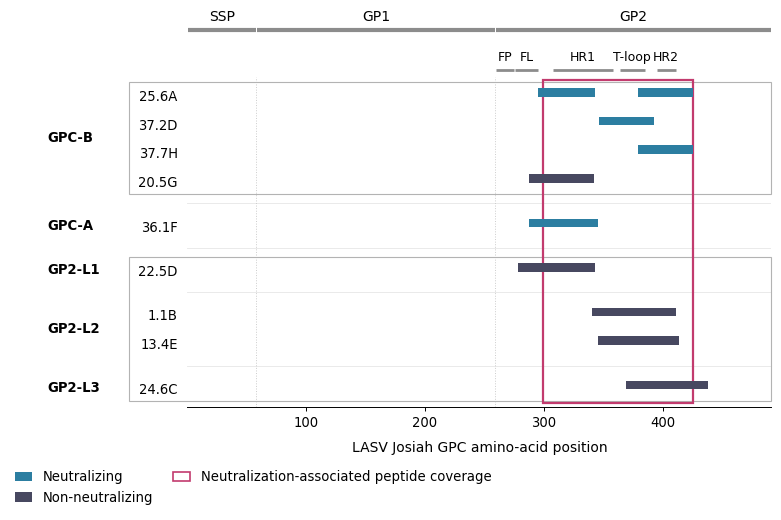

In [65]:
cohort_regions = [
    (300, 425)
    # (start, end),
]

fig, ax = plot_mab_coverage(
    mab_results=mab_results,
    ref_length=ref_length,
    cohort_regions=cohort_regions,
    figsize=(8, 5)
    # order=mab_order,  # Optional custom order
)

plt.show()

fig.savefig("mAb_coverage.svg", bbox_inches="tight")
fig.savefig("mAb_coverage.png", dpi=600, bbox_inches="tight")

### remove 36.1F to keep it GPC-B focused

In [66]:
plot_results = {
    name: result
    for name, result in mab_results.items()
    if name != "36.1F"
}

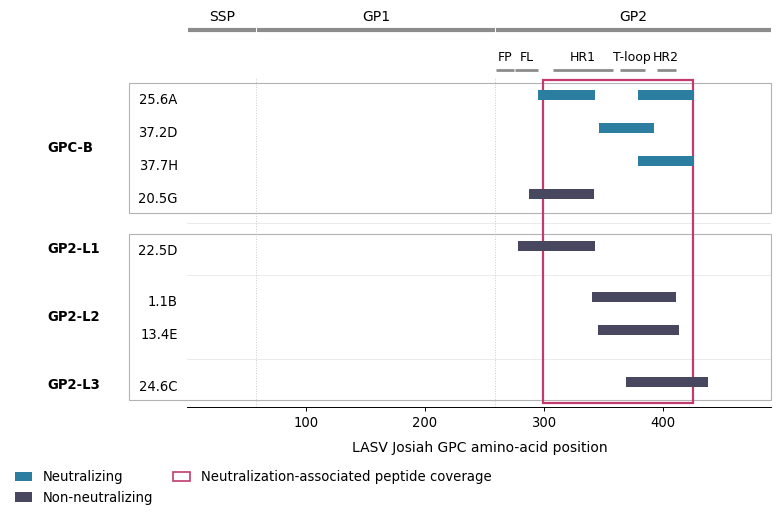

In [67]:
cohort_regions = [
    (300, 425)
    # (start, end),
]

fig, ax = plot_mab_coverage(
    mab_results=plot_results,
    ref_length=ref_length,
    cohort_regions=cohort_regions,
    figsize=(8, 5)
    # order=mab_order,  # Optional custom order
)

plt.show()

fig.savefig("mAb_coverage_only_GPCB.svg", bbox_inches="tight")
fig.savefig("mAb_coverage_only_GPCB.png", dpi=600, bbox_inches="tight")

In [68]:
mab_results

{'1.1B': {'pearsons_r': np.float64(0.9969547775470267),
  'top_peptides': ['YCNYSKFWYLEHAKTGETSVPKCWLVTNGSYLNETHFSDQIEQEAD',
   'YSKFWYLEHYKTGETSLPKCWLVSNGSYLNETHFSTEIEQEADNMI',
   'YSKFWYLEHYKTGETSLPKCWLVSNGSYLNETHFSDEIEQEANNMI',
   'TVTPLISDQLLMRNHLRDLMGVPYCNSSKFWYLEHAKTGETSVPKC',
   'TVNSLISDQLLMRNHLRDLMGVPYCNYSKFWYLEHVKTKETSVPKC'],
  'peptides enrichment values': peptide
  ABM46592.1|precursor|Mammarenavirus_choriomeningitidis|?|Homo_sapiens|France|?|S|LE|tile_16                          572.169438
  YP_006858706.1|precursor|Lunk_virus_NKS-1|?|Mus_minutoides|Zambia:Lusaka|10-Aug-2010|S|NKS-1|tile_17                 559.508498
  WDW20703.1|precursor|Ngerengere_mammarenavirus|TZ23187|Mus_minutoides_SE|Tanzania:_Mkundi|08-Dec-2009|S|?|tile_17    491.390222
  XOB76280.1|glycoprotein|Mammarenavirus_ryukyuense|CXMIX-YNSF117|Mus_musculus|China:_Yunnan|2021|S|?|tile_17          468.577622
  AFI42021.1|precursor|Mammarenavirus_choriomeningitidis|?|Mus_musculus|France|Oct-2009|S|HP65-2009/1|